# Quality assessment of the 2D reference labels

This notebook assesses the delivered 2D reference labels for both study sites without re-annotation. It follows the label from the drawn polygon to the array a model reads, in four checks: **annotation integrity** (invalid geometry, cross-class overlap, polygons below the MMU); **label preservation** from polygon to 1 cm raster to 5 cm label grid; **grid agreement** between the label grid and the predictor grid, with per-feature centroid RMSE, polygon IoU and grid offset; and **boundary sensitivity** to a ±5 cm delineation shift.

Agreement is reported as class-wise **IoU**, given throughout as **mean / median** pooled over tiles and classes. Both are shown because they disagree informatively: a mean well below its median means a single class or a few tiles are failing alone rather than the labels being uniformly poor, which is the case at both sites and for different reasons.

The available data do not support estimates of annotation accuracy against field truth or inter-annotator reproducibility because neither field labels nor repeat annotations are available. Delineation sensitivity is therefore reported as a bound on geometric uncertainty, not as observed agreement.


In [ ]:
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd


def find_repo_root(start: Path) -> Path:
    marker = Path('phase_3_2D_imagery_prep/step_3_label_quality/label_qa.py')
    for candidate in [start, *start.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f'Could not locate repository root from {start}')


REPO_ROOT = find_repo_root(Path.cwd().resolve())
STEP_DIR = REPO_ROOT / 'phase_3_2D_imagery_prep' / 'step_3_label_quality'
if str(STEP_DIR) not in sys.path:
    sys.path.insert(0, str(STEP_DIR))

from label_qa import CLASS_LABELS, DEFAULT_BOUNDARY_M, read_annotations, wsl_path

SITES = [
    # `figure_tile` is the tile drawn by the centroid figure. 26 is one of only two
    # medium-site tiles whose label and predictor grids are offset from each other; on
    # the other thirteen the two footprints are identical and the figure shows nothing.
    # `font_size` is larger at the medium site: its figure has four growth-form columns,
    # so it is scaled down more when fit to \textwidth and needs bigger type to stay legible.
    {'site': 'site1_1_DD0001', 'condition': 'Medium', 'shp_subdir': 'annotations_shp',
     'figure_tile': '26', 'font_size': 22},
    {'site': 'site2_1_DD0011', 'condition': 'Low', 'shp_subdir': 'annotation_shp',
     'figure_tile': '25', 'font_size': 16},
]
FORCE_RERUN = False


def site_paths(config):
    base = wsl_path(rf"D:\paper2\data\calperumResearch\{config['site']}")
    mask = base / 'imagery' / 'inputs' / 'masks' / 'tiles_3072' / 'raw' / 'structure_class'
    raster = mask / 'annotation_raster'
    predictors = base / 'imagery' / 'inputs' / 'predictors' / 'tiles_3072'
    image = next((path for path in (
        predictors / 'multispec' / 'res_05' / 'stacked', predictors / 'stacked'
    ) if path.exists()), None)
    return {
        'shp': mask / config['shp_subdir'],
        'raster': raster,
        'coarse': raster / 'downsample_5cm_nearest',
        'image': image,
        'rgb': predictors / 'rgb',
        'out': base / 'lidar' / 'clipped' / 'validation' / 'label_quality',
    }


DATA = {}
for config in SITES:
    paths = site_paths(config)
    summary_csv = paths['out'] / f"{config['site']}_qa_summary.csv"
    issues_csv = paths['out'] / f"{config['site']}_qa_issues.csv"
    if FORCE_RERUN or not summary_csv.exists():
        command = [
            sys.executable, str(STEP_DIR / 'label_qa.py'),
            '--site', config['site'], '--site-condition', config['condition'],
            '--shp-dir', str(paths['shp']), '--raster-dir', str(paths['raster']),
            '--downsampled-dir', str(paths['coarse']),
            *(['--image-dir', str(paths['image'])] if paths['image'] else []),
            '--output-dir', str(paths['out']),
        ]
        result = subprocess.run(command, text=True, capture_output=True)
        if result.returncode:
            raise RuntimeError(result.stderr[-3000:])

    summary = pd.read_csv(summary_csv)
    DATA[config['condition']] = {
        **config,
        'tiles': summary[~summary['Tile'].isin(['Average', 'Median'])].copy(),
        'average': summary[summary['Tile'] == 'Average'].iloc[0],
        'median': summary[summary['Tile'] == 'Median'].iloc[0],
        'issues': pd.read_csv(issues_csv),
    }

print('Loaded:', ', '.join(
    f"{condition} ({len(data['tiles'])} tiles)" for condition, data in DATA.items()
))


Loaded: Medium (15 tiles), Low (15 tiles)


In [2]:
from IPython.display import Markdown, display


def site_label(d):
    return f"{d['condition']} ({d['site'].split('_')[-1]})"


def iou_values(tiles, prefix):
    """Every per-tile, per-class IoU under one prefix; classes absent from the site drop out."""
    columns = [f'{prefix} {name}' for name in CLASS_LABELS.values() if f'{prefix} {name}' in tiles]
    values = [tiles[c].dropna() for c in columns]
    values = [v for v in values if not v.empty]
    return pd.concat(values, ignore_index=True) if values else pd.Series(dtype=float)


def mean_median(tiles, prefix):
    """Mean and median pooled over tiles and classes. They part company when one class fails."""
    v = iou_values(tiles, prefix)
    return 'not measured' if v.empty else f'{v.mean():.3f} / {v.median():.3f}'


# Each metric as (mean, median) across tiles. `pooled` pools a class IoU family over tiles and
# classes; `column` takes one per-tile column; `polygon` pairs the mean of per-tile means with
# the median of per-tile medians, since each tile already reduces over its polygons.
def pooled(prefix, digits=3):
    return lambda t: (lambda v: (v.mean(), v.median(), digits))(iou_values(t, prefix))

def column(name, digits=3):
    return lambda t: (t[name].mean(), t[name].median(), digits)

def polygon(stage, digits=3):
    return lambda t: (t[f'Polygon IoU mean {stage}'].mean(),
                      t[f'Polygon IoU median {stage}'].median(), digits)


# The assessment, in the order a label travels from the drawn polygon to the array a model reads.
CHECKS = [
    ('1. Annotation QA', 'Invalid geometries per tile', column('Invalid geometries', 1)),
    ('1. Annotation QA', 'Cross-class overlap (% of labelled area)', column('Cross-class overlap (%)')),
    ('1. Annotation QA', 'Polygons below MMU (%)', column('Below MMU (%)', 2)),
    ('2. Polygon -> 1 cm raster', 'Class IoU', pooled('IoU 1 cm')),
    ('3. 1 cm -> 5 cm label grid', 'Class IoU', pooled('IoU 5 cm')),
    ('3. 1 cm -> 5 cm label grid', 'Polygon IoU', polygon('5 cm')),
    ('3. 1 cm -> 5 cm label grid', 'Centroid RMSE (m)', column('Centroid RMSE 5 cm (m)', 4)),
    ('4. Label grid -> predictor grid', 'Class IoU', pooled('IoU predictor')),
    ('4. Label grid -> predictor grid', 'Polygon IoU', polygon('predictor')),
    ('4. Label grid -> predictor grid', 'Centroid RMSE (m)', column('Centroid RMSE predictor (m)', 4)),
    ('4. Label grid -> predictor grid', 'Grid offset (cm)', column('Predictor grid offset (cm)', 2)),
    ('4. Label grid -> predictor grid', 'Predictor GSD (cm)', column('Predictor GSD (cm)', 1)),
    (f'5. +/-{DEFAULT_BOUNDARY_M * 100:.0f} cm boundary perturbation', 'Delineation IoU',
     pooled('Delineation IoU')),
]

cells = {}
for d in DATA.values():
    for check, metric, measure in CHECKS:
        mean, median, digits = measure(d['tiles'])
        cells[(site_label(d), 'Mean'), (check, metric)] = f'{mean:.{digits}f}'
        cells[(site_label(d), 'Median'), (check, metric)] = f'{median:.{digits}f}'

qa_table = pd.Series(cells).unstack(level=0)
qa_table = qa_table.reindex(index=pd.MultiIndex.from_tuples([(c, m) for c, m, _ in CHECKS]),
                            columns=pd.MultiIndex.from_tuples(list(dict.fromkeys(k[0] for k in cells))))
qa_table.index.names = ['Check', 'Metric']
display(qa_table)

# Class IoU per class at each step, where a class failing alone is visible rather than pooled.
STEPS = {'Polygon -> 1 cm': 'IoU 1 cm', '1 cm -> 5 cm': 'IoU 5 cm',
         'Label -> predictor': 'IoU predictor', 'Delineation (+/-5 cm)': 'Delineation IoU'}
per_class = pd.DataFrame({
    (site_label(d), name): {
        step: f"{d['tiles'][f'{prefix} {name}'].mean():.3f} / "
              f"{d['tiles'][f'{prefix} {name}'].median():.3f}"
        for step, prefix in STEPS.items()
    }
    for d in DATA.values() for name in CLASS_LABELS.values()
    if d['tiles'][f'IoU 1 cm {name}'].notna().any()
}).T
per_class.index.names = ['Site', 'Class']
per_class.columns.name = 'Class IoU, mean / median across tiles'
display(per_class)

medium, low = DATA['Medium'], DATA['Low']
low_woody = low['tiles']['IoU 1 cm Woody debris']
low_others = iou_values(
    low['tiles'].drop(columns=['IoU 1 cm Woody debris']), 'IoU 1 cm')

response = f"""
## Quality assessment summary

The delivered 2D reference labels were assessed for both sites
({len(medium['tiles'])} medium-condition tiles and {len(low['tiles'])} low-condition tiles)
without re-annotation. Agreement is reported as class-wise IoU at each lossy step between the
drawn polygon and the array a model reads, pooled over tiles and classes and given as
**mean / median**; the two part company exactly where one class or a few tiles fail
differently from the rest, so the gap between them is itself a result.

Between the **polygon and the delivered 1 cm raster** the labels score
**{mean_median(medium['tiles'], 'IoU 1 cm')}** at the medium site and
**{mean_median(low['tiles'], 'IoU 1 cm')}** at the low site. The low site's mean sits well
below its median because one class fails alone: Woody debris scores
**{low_woody.mean():.3f}** where every other class stays above
**{low_others.min():.3f}**. That is stale shapefiles
retaining `unknown` polygons, not a rasterisation error -- the delivered raster the
experiments consume excludes them.

Through the **1 cm to 5 cm downsample** the labels score
**{mean_median(medium['tiles'], 'IoU 5 cm')}** and
**{mean_median(low['tiles'], 'IoU 5 cm')}**.

Against the **predictor grid** the labels score
**{mean_median(medium['tiles'], 'IoU predictor')}** and
**{mean_median(low['tiles'], 'IoU predictor')}**. Medium-site predictors are
**{medium['average']['Predictor GSD (cm)']:.1f} cm** with an origin offset of
**{medium['average']['Predictor grid offset (cm)']:.1f} cm** from the label grid on average;
low-site predictors are **{low['average']['Predictor GSD (cm)']:.1f} cm** against 5 cm labels.
Labels should be warped directly onto each predictor grid before fitting and evaluation.

Annotation itself is internally consistent: cross-class overlap covers
**{medium['average']['Cross-class overlap (%)']:.3f}%** and
**{low['average']['Cross-class overlap (%)']:.3f}%** of labelled area, invalid geometries
average **{medium['average']['Invalid geometries']:.1f}** and
**{low['average']['Invalid geometries']:.1f}** per tile, and
**{medium['average']['Below MMU (%)']:.1f}%** and **{low['average']['Below MMU (%)']:.1f}%**
of polygons fall below the minimum mapping unit, each logged individually for repair.

Position and overlap were then separated per feature, following Haynes et al. (2025), who
co-register UAS imaging spectroscopy to RGB and report both the RMSE of centroid
displacement and the mean/median IoU of digitised features. Each labelled polygon here is
compared against its own footprint on the grid before it. Through the 1 cm to 5 cm step,
centroids barely move -- RMSE **{medium['tiles']['Centroid RMSE 5 cm (m)'].mean():.3f} m** and
**{low['tiles']['Centroid RMSE 5 cm (m)'].mean():.3f} m**, well inside one cell -- while
per-feature IoU falls to **{medium['tiles']['Polygon IoU mean 5 cm'].mean():.3f}** and
**{low['tiles']['Polygon IoU mean 5 cm'].mean():.3f}**; from the label grid to the predictor
grid, features move **{medium['tiles']['Centroid RMSE predictor (m)'].mean():.3f} m** and
**{low['tiles']['Centroid RMSE predictor (m)'].mean():.3f} m** and keep polygon IoU
**{medium['tiles']['Polygon IoU mean predictor'].mean():.3f}** and
**{low['tiles']['Polygon IoU mean predictor'].mean():.3f}**. The labels are therefore in the
right *place* and the wrong *shape*: individual features are eroded and dilated by
quantisation rather than shifted off their ground. That distinction matters for how the
labels are used, because a shift is correctable by a warp and a shape change is not. Note
that Haynes et al. compare two independent delineations of one feature, whereas only one
delineation exists here, so these columns bound the cost of the grids, not of the annotator.

No repeat annotation exists, so inter-annotator reproducibility and accuracy against field
truth are not claimed. In their place, a +/-{DEFAULT_BOUNDARY_M * 100:.0f} cm delineation
sensitivity is reported as a geometric floor (IoU
**{mean_median(medium['tiles'], 'Delineation IoU')}** and
**{mean_median(low['tiles'], 'Delineation IoU')}**) -- the agreement two delineations
disagreeing by one 5 cm cell everywhere would still reach.
"""
display(Markdown(response))


Medium (DD0001)  \
                                                                                     Mean   
Check                            Metric                                                     
1. Annotation QA                 Invalid geometries per tile                          7.6   
                                 Cross-class overlap (% of labelled area)           0.021   
                                 Polygons below MMU (%)                              1.38   
2. Polygon -> 1 cm raster        Class IoU                                          0.924   
3. 1 cm -> 5 cm label grid       Class IoU                                          0.806   
                                 Polygon IoU                                        0.809   
                                 Centroid RMSE (m)                                 0.0117   
4. Label grid -> predictor grid  Class IoU                                          0.784   
                                 Polygon IoU                                        0.972   
                                 Centroid RMSE (m)                                 0.0022   
                                 Grid offset (cm)                                    0.27   
                                 Predictor GSD (cm)                                   5.0   
5. +/-5 cm boundary perturbation Delineation IoU                                    0.321   

                                                                                   \
                                                                           Median   
Check                            Metric                                             
1. Annotation QA                 Invalid geometries per tile                  0.0   
                                 Cross-class overlap (% of labelled area)   0.000   
                                 Polygons below MMU (%)                      0.85   
2. Polygon -> 1 cm raster        Class IoU                                  0.934   
3. 1 cm -> 5 cm label grid       Class IoU                                  0.804   
                                 Polygon IoU                                0.803   
                                 Centroid RMSE (m)                         0.0100   
4. Label grid -> predictor grid  Class IoU                                  0.782   
                                 Polygon IoU                                1.000   
                                 Centroid RMSE (m)                         0.0000   
                                 Grid offset (cm)                            0.00   
                                 Predictor GSD (cm)                           5.0   
5. +/-5 cm boundary perturbation Delineation IoU                            0.254   

                                                                          Low (DD0011)  \
                                                                                  Mean   
Check                            Metric                                                  
1. Annotation QA                 Invalid geometries per tile                       0.8   
                                 Cross-class overlap (% of labelled area)        0.161   
                                 Polygons below MMU (%)                           0.68   
2. Polygon -> 1 cm raster        Class IoU                                       0.679   
3. 1 cm -> 5 cm label grid       Class IoU                                       0.996   
                                 Polygon IoU                                     0.878   
                                 Centroid RMSE (m)                              0.0069   
4. Label grid -> predictor grid  Class IoU                                       0.930   
                                 Polygon IoU                                     0.859   
                                 Centroid RMSE (m)                              0.0123   
                                 Grid offset (cm)     

Class IoU, mean / median across tiles Polygon -> 1 cm   1 cm -> 5 cm  \
Site            Class                                                  
Medium (DD0001) Woody debris            0.853 / 0.868  0.678 / 0.644   
                Grass                   0.920 / 0.927  0.775 / 0.769   
                Shrub                   0.939 / 0.940  0.825 / 0.805   
                Mallee                  0.984 / 0.984  0.949 / 0.943   
Low (DD0011)    Forb                    0.955 / 0.955  0.995 / 0.995   
                Woody debris            0.014 / 0.000  0.991 / 0.994   
                Shrub                   0.980 / 0.980  0.999 / 0.999   

Class IoU, mean / median across tiles Label -> predictor Delineation (+/-5 cm)  
Site            Class                                                           
Medium (DD0001) Woody debris               0.642 / 0.644         0.039 / 0.019  
                Grass                      0.752 / 0.769         0.214 / 0.214  
                Shrub                      0.801 / 0.804         0.294 / 0.299  
                Mallee                     0.944 / 0.943         0.735 / 0.732  
Low (DD0011)    Forb                       0.914 / 0.915         0.406 / 0.400  
                Woody debris               0.882 / 0.911         0.349 / 0.410  
                Shrub                      0.958 / 0.959         0.652 / 0.662


## Quality assessment summary

The delivered 2D reference labels were assessed for both sites
(15 medium-condition tiles and 15 low-condition tiles)
without re-annotation. Agreement is reported as class-wise IoU at each lossy step between the
drawn polygon and the array a model reads, pooled over tiles and classes and given as
**mean / median**; the two part company exactly where one class or a few tiles fail
differently from the rest, so the gap between them is itself a result.

Between the **polygon and the delivered 1 cm raster** the labels score
**0.924 / 0.934** at the medium site and
**0.679 / 0.957** at the low site. The low site's mean sits well
below its median because one class fails alone: Woody debris scores
**0.014** where every other class stays above
**0.934**. That is stale shapefiles
retaining `unknown` polygons, not a rasterisation error -- the delivered raster the
experiments consume excludes them.

Through the **1 cm to 5 cm downsample** the labels score
**0.806 / 0.804** and
**0.996 / 0.997**.

Against the **predictor grid** the labels score
**0.784 / 0.782** and
**0.930 / 0.941**. Medium-site predictors are
**5.0 cm** with an origin offset of
**0.3 cm** from the label grid on average;
low-site predictors are **6.0 cm** against 5 cm labels.
Labels should be warped directly onto each predictor grid before fitting and evaluation.

Annotation itself is internally consistent: cross-class overlap covers
**0.021%** and
**0.161%** of labelled area, invalid geometries
average **7.6** and
**0.8** per tile, and
**1.4%** and **0.7%**
of polygons fall below the minimum mapping unit, each logged individually for repair.

Position and overlap were then separated per feature, following Haynes et al. (2025), who
co-register UAS imaging spectroscopy to RGB and report both the RMSE of centroid
displacement and the mean/median IoU of digitised features. Each labelled polygon here is
compared against its own footprint on the grid before it. Through the 1 cm to 5 cm step,
centroids barely move -- RMSE **0.012 m** and
**0.007 m**, well inside one cell -- while
per-feature IoU falls to **0.809** and
**0.878**; from the label grid to the predictor
grid, features move **0.002 m** and
**0.012 m** and keep polygon IoU
**0.972** and
**0.859**. The labels are therefore in the
right *place* and the wrong *shape*: individual features are eroded and dilated by
quantisation rather than shifted off their ground. That distinction matters for how the
labels are used, because a shift is correctable by a warp and a shape change is not. Note
that Haynes et al. compare two independent delineations of one feature, whereas only one
delineation exists here, so these columns bound the cost of the grids, not of the annotator.

No repeat annotation exists, so inter-annotator reproducibility and accuracy against field
truth are not claimed. In their place, a +/-5 cm delineation
sensitivity is reported as a geometric floor (IoU
**0.321 / 0.254** and
**0.508 / 0.547**) -- the agreement two delineations
disagreeing by one 5 cm cell everywhere would still reach.


Wrote: /home/uqlsoto1/code_phd/fvc_structure/phase_3_2D_imagery_prep/step_3_label_quality/label_centroids.png


**Medium site (DD0001), tile 26**  ·  `label_centroids.png`

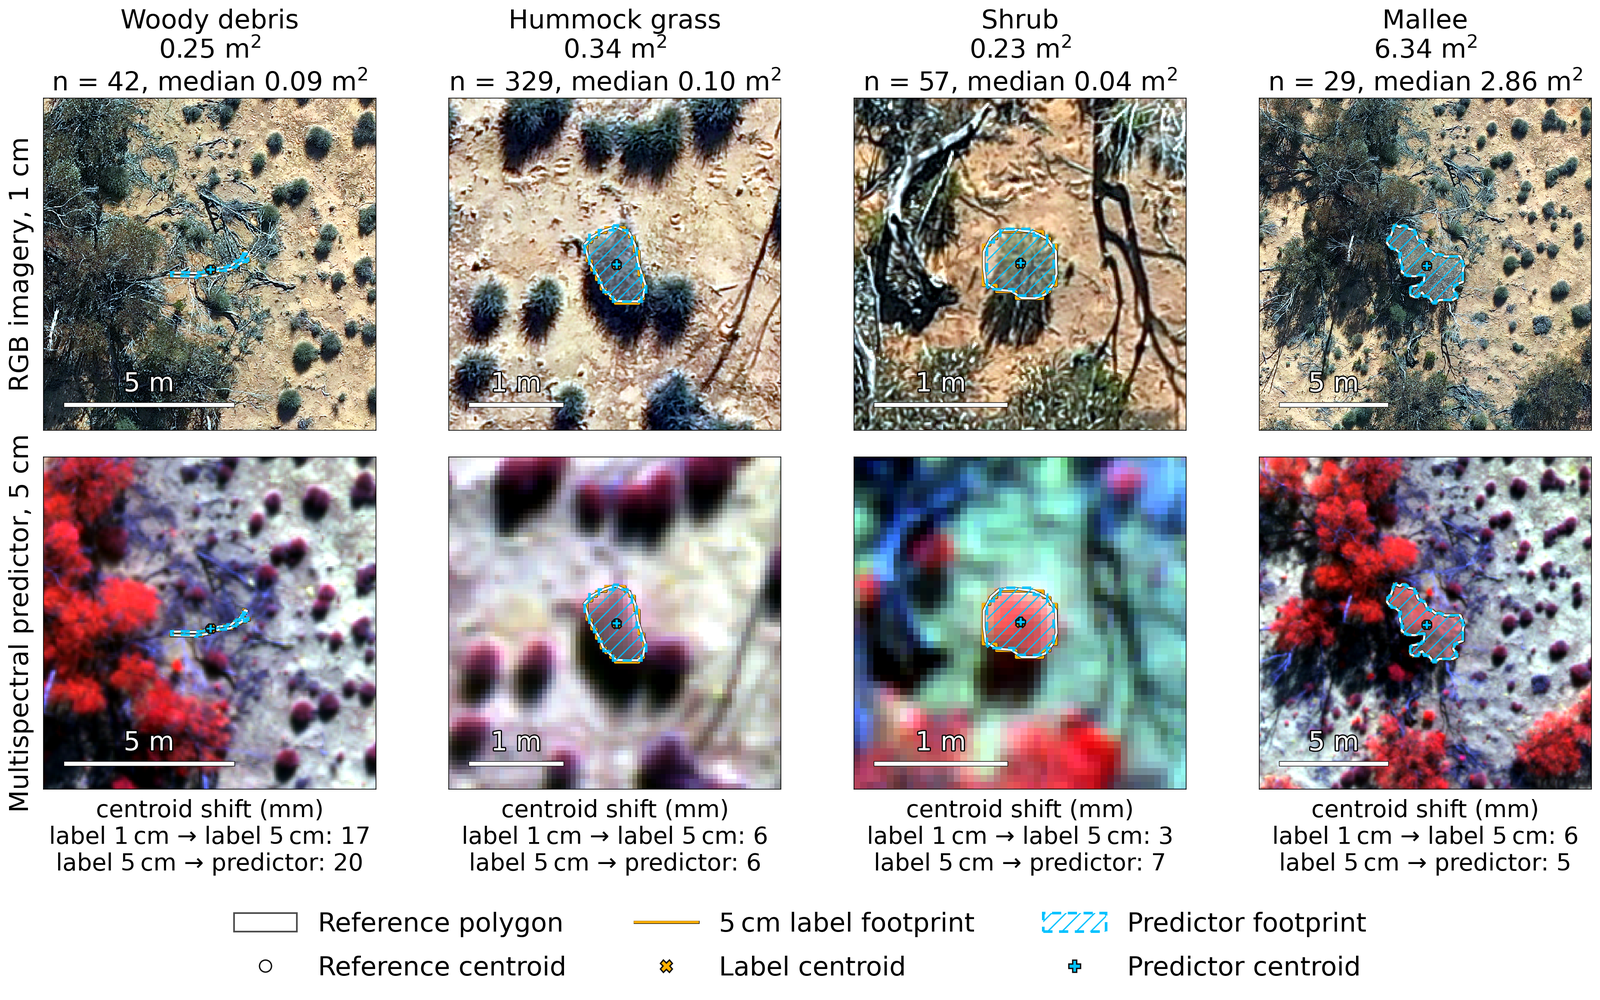

Excluded 1 polygon(s) with structure in ['unknown']: 127.1 m2


**Low site (DD0011), tile 25**  ·  `label_centroids_low.png`

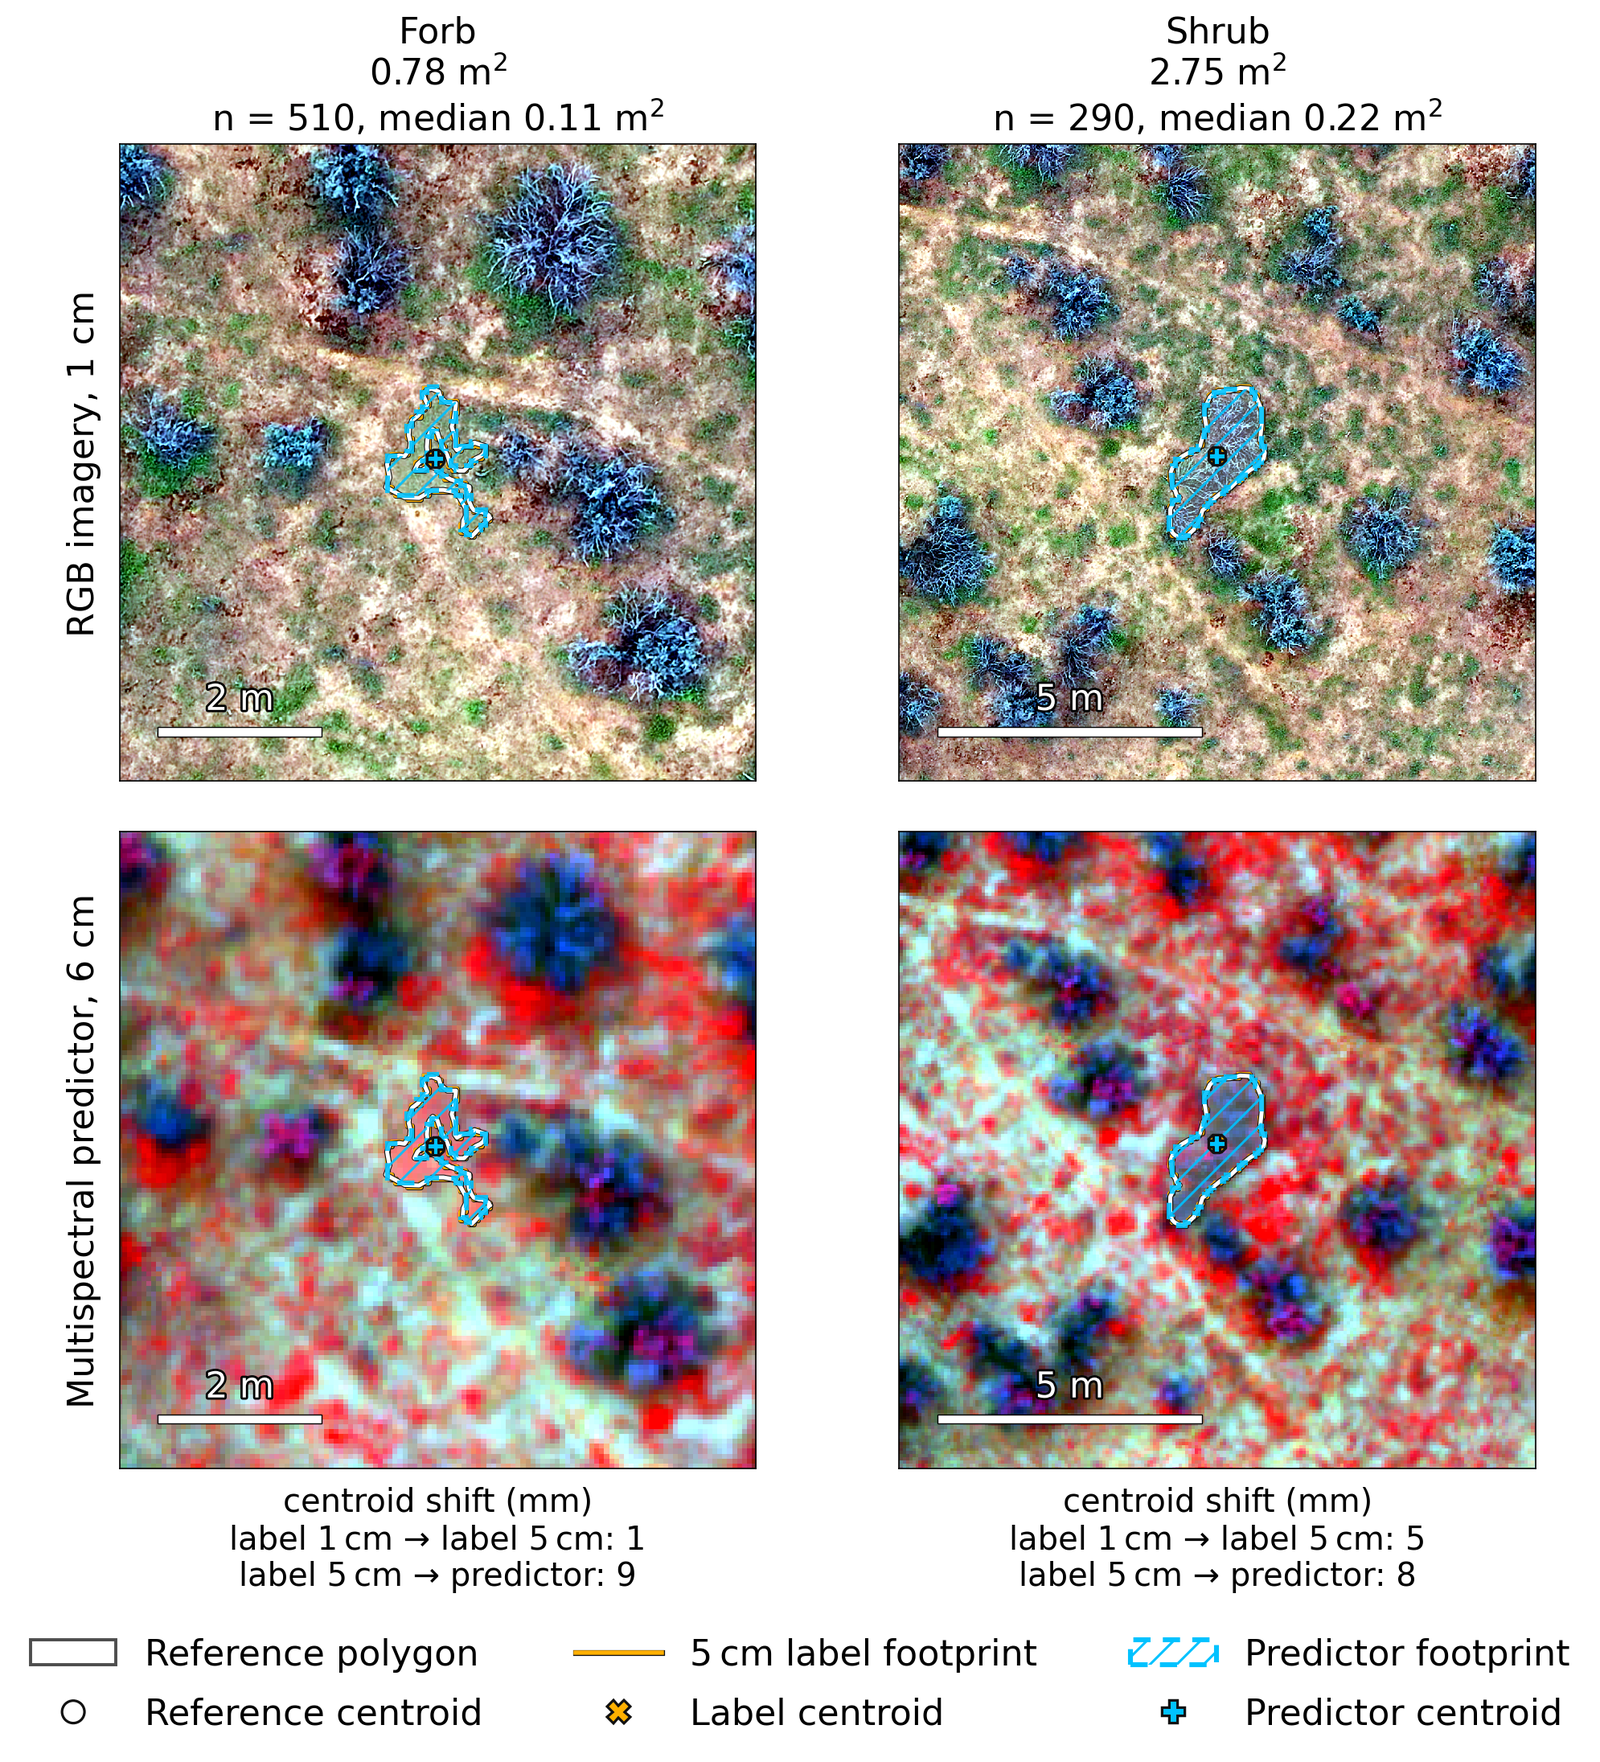

In [3]:
import io

from IPython.display import Image, display
from PIL import Image as PILImage

# The per-feature numbers above say centroids barely move while per-feature IoU falls.
# That is a claim about geometry, so it is drawn rather than asserted: one column per
# growth form, the 1 cm RGB the polygons were digitised on above the predictor raster the
# models read, with the reference polygon, the label raster and the predictor raster overlaid.
FIGURE_DIR = STEP_DIR
REDRAW = True
PREVIEW_WIDTH = 1600


def preview(path, width):
    """A downscaled copy for display. The file on disk stays at full resolution for
    the manuscript; embedding it verbatim would put ~10 MB of base64 in the notebook
    for every figure, which is slow to open and pointless on screen."""
    with PILImage.open(path) as image:
        if image.width > width:
            image = image.resize((width, round(image.height * width / image.width)),
                                 PILImage.LANCZOS)
        buffer = io.BytesIO()
        image.convert('RGB').save(buffer, format='PNG', optimize=True)
    return buffer.getvalue()

for config in SITES:
    paths = site_paths(config)
    stem = 'label_centroids' if config['condition'] == 'Medium' else 'label_centroids_low'
    png = FIGURE_DIR / f'{stem}.png'
    if REDRAW or not png.exists():
        command = [
            sys.executable, str(STEP_DIR / 'plot_centroids.py'),
            '--site', config['site'], '--tile', config['figure_tile'],
            '--shp-dir', str(paths['shp']), '--raster-dir', str(paths['raster']),
            '--downsampled-dir', str(paths['coarse']), '--image-dir', str(paths['image']),
            *(['--rgb-dir', str(paths['rgb'])] if paths['rgb'].exists() else []),
            *(['--font-size', str(config['font_size'])] if config.get('font_size') else []),
            '--output', str(FIGURE_DIR / stem),
        ]
        result = subprocess.run(command, text=True, capture_output=True)
        if result.returncode:
            raise RuntimeError(result.stderr[-3000:])
        print(result.stdout.strip().splitlines()[0] if result.stdout.strip() else '')

    display(Markdown(f"**{config['condition']} site ({config['site'].split('_')[-1]}), "
                     f"tile {config['figure_tile']}**  ·  `{png.name}`"))
    display(Image(data=preview(png, PREVIEW_WIDTH)))


## How to read the figures

Each figure shows one tile: **tile 26** at the medium site and **tile 25** at the low site. Each column shows one example polygon per growth form, selected near the 95th percentile of class area so that it covers enough cells to be legible.

**Rows.** The top row is the 1 cm RGB imagery. The bottom row is the multispectral predictor imagery (5 cm at the medium site, 6 cm at the low site), shown as a false-colour composite of bands 5, 3 and 1, with near-infrared in red, so vegetation appears red.

**Column headings** give three numbers, e.g. *Woody debris / 0.25 m² / n = 42, median 0.09 m²*:

| Line | Meaning |
|---|---|
| `0.25 m²` | area of the example polygon drawn in the column |
| `n = 42` | number of polygons of that class in the tile |
| `median 0.09 m²` | median area of those polygons, so the example can be read against a typical one |

**Overlays** (legend at the bottom):

| Symbol | Meaning |
|---|---|
| Reference polygon, ○ Reference centroid | the digitised polygon and its centre |
| 5 cm label footprint, × Label centroid | the 5 cm label raster cells assigned to the polygon, and their centre |
| Predictor footprint, + Predictor centroid | the predictor raster cells assigned to the polygon, and their centre |

**Centroid shift (mm)**, below each column, compares each raster with the one before it, the same comparison as the centroid RMSE rows in the QA table:

| Line | Meaning |
|---|---|
| `label 1 cm → label 5 cm` | how far the feature's centre moves when the 1 cm labels are downsampled to 5 cm |
| `label 5 cm → predictor` | how far apart the 5 cm label and the predictor pixels it is paired with place the feature's centre |

The figures show single examples; the QA table summarises every polygon on every tile.

**Medium site.** Tile 26 is one of two medium-site tiles on which the label and predictor rasters have an origin offset, so their footprints separate. On the remaining 13 tiles the two rasters share an origin and a 5 cm cell, so the footprints are identical and the label → predictor shift is zero.

**Low site.** The 5 cm labels and the 6 cm predictor raster share an origin but differ in cell size, so their footprints cannot align cell for cell on any tile. Every feature is affected a little, rather than a few tiles being affected a lot.

In both figures the footprints differ visibly along feature boundaries while the centroids stay within a few millimetres: rasterisation changes feature shape far more than feature position.

In [4]:
# `label_qa.py` measures this per polygon and writes two columns; reading them back
# keeps one implementation of the comparison rather than a second one here that can drift.
# It is scored on the 5 cm grid, the resolution the models and the 3D work consume:
# disagreement finer than one 5 cm cell is not something either can express.
def grids(row):
    """The two grids either interlock or they cannot, and the two failures behave
    differently: a shifted origin spares most tiles and ruins a couple, a different
    pixel size costs every feature on every tile. Pooling them would hide both."""
    if abs(row['Predictor GSD (cm)'] - 5.0) > 0.01:
        return f"{row['Predictor GSD (cm)']:.0f} cm pixels on 5 cm cells"
    return 'same origin' if row['Predictor grid offset (cm)'] < 0.1 else 'origins offset'


rows = []
for condition, data in DATA.items():
    tiles = data['tiles'].copy()
    tiles['Grids'] = tiles.apply(grids, axis=1)
    for name, block in tiles.groupby('Grids'):
        w = block['Polygons']
        rows.append({
            'Site': f"{condition} ({data['site'].split('_')[-1]})", 'Grids': name,
            'Tiles': len(block), 'Polygons': int(w.sum()),
            'Footprint IoU (mean / median)':
                f"{np.average(block['Polygon IoU mean predictor'], weights=w):.3f} / "
                f"{np.average(block['Polygon IoU median predictor'], weights=w):.3f}",
        })

display(pd.DataFrame(rows).set_index(['Site', 'Grids']))


Tiles  Polygons  \
Site            Grids                                        
Medium (DD0001) origins offset                 2       692   
                same origin                   13      5425   
Low (DD0011)    6 cm pixels on 5 cm cells     15      6199   

                                          Footprint IoU (mean / median)  
Site            Grids                                                    
Medium (DD0001) origins offset                            0.788 / 0.804  
                same origin                               1.000 / 1.000  
Low (DD0011)    6 cm pixels on 5 cm cells                 0.854 / 0.877